# EDA: детекция ботов-парсеров
Разведочный анализ данных. Выводы собраны в конце ноутбука.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src import config, data
pd.set_option('display.width', 200, 'display.max_columns', 40)
tr, te, ev = data.load_train(), data.load_test(), data.load_events()
meta = pd.concat([tr, te.assign(target=np.nan)], ignore_index=True)
meta['split'] = np.where(meta.target.isna(), 'test', 'train')
print(tr.shape, te.shape, ev.shape)
print(ev.dtypes)

(11091, 5) (4909, 4) (328905, 14)
cookie_id                        str
event_ts         datetime64[us, UTC]
eid                            int64
event_name                       str
platform                         str
user_agent                       str
item_id                       string
item_category                    str
item_location                    str
seller_type                      str
search_query                     str
search_page                  float64
pointer_x                    float64
pointer_y                    float64
dtype: object


## 1. Баланс классов и время

target
0    10192
1      899
Name: count, dtype: int64 
доля ботов: 0.0811
длина окон: {Timedelta('1 days 00:00:00'): 16000}
cookie_created_at > window_start: 0
event_ts tz: UTC | дробные секунды: 0


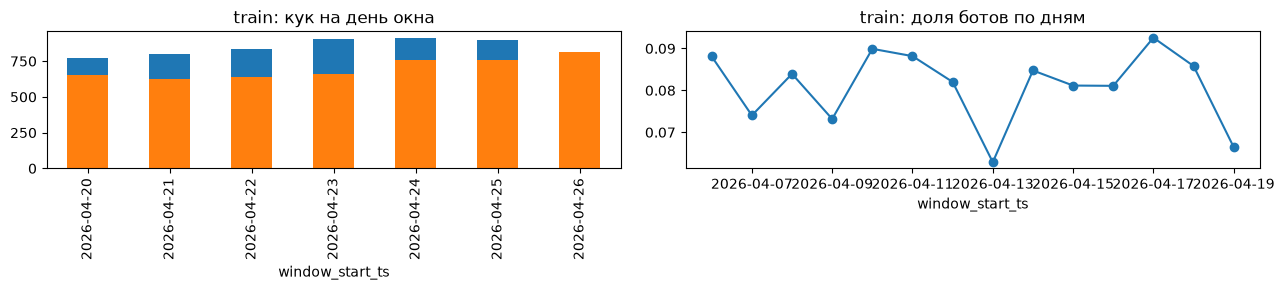

In [2]:
print(tr.target.value_counts(), '\nдоля ботов:', tr.target.mean().round(4))
print('длина окон:', (meta.window_end_ts - meta.window_start_ts).value_counts().to_dict())
print('cookie_created_at > window_start:', (meta.cookie_created_at > meta.window_start_ts).sum())
print('event_ts tz:', ev.event_ts.dt.tz, '| дробные секунды:', (ev.event_ts.dt.microsecond != 0).sum())
by_day = tr.groupby(tr.window_start_ts.dt.date).target.agg(['size', 'mean'])
fig, ax = plt.subplots(1, 2, figsize=(13, 3))
by_day['size'].plot.bar(ax=ax[0], title='train: кук на день окна')
te.window_start_ts.dt.date.value_counts().sort_index().plot.bar(ax=ax[0], color='C1')
by_day['mean'].plot(ax=ax[1], marker='o', title='train: доля ботов по дням'); plt.tight_layout()

## 2. События вне окна
Окно беру полуоткрытым, `[window_start_ts, window_end_ts)`: оно идёт ровно с 00:00 до 00:00, и событие ровно в `window_end_ts` относится уже к следующему дню.

In [3]:
m = ev.merge(meta, on='cookie_id')
t, s, e = m.event_ts, m.window_start_ts, m.window_end_ts
m['inw'] = (t >= s) & (t < e)
print('до начала:', (t < s).sum(), '| ровно на start:', (t == s).sum(), '| ровно на end:', (t == e).sum(), '| после end:', (t > e).sum())
print('вне окна по split:', m[~m.inw].groupby('split').size().to_dict())
print('доля кук с событиями вне окна по target:', m.groupby('cookie_id').inw.apply(lambda x: (~x).any()).to_frame()
      .join(meta.set_index('cookie_id').target).groupby('target', dropna=False).inw.mean().round(3).to_dict())
print(pd.crosstab(m.event_name, m.inw))
print('captcha_shown по target:', m[m.event_name == 'captcha_shown'].target.value_counts(dropna=False).to_dict())

до начала: 0 | ровно на start: 0 | ровно на end: 68 | после end: 40711
вне окна по split: {'train': 40779}


доля кук с событиями вне окна по target: {0.0: 0.45, 1.0: 0.77, nan: 0.0}
inw                   False   True 
event_name                         
captcha_shown          7928       0
contact_chat_open       577    5548
contact_message_sent    258    2823
contact_phone_show     1028   10288
favorite_add           1753   17296
item_view             12731  108086
login                   606    5661
photo_swipe            3433   33084
search_results_view   10604   89798
seller_page_view       1861   15542
captcha_shown по target: {1.0: 6970, 0.0: 958}


## 3. Дубликаты

In [4]:
w = m[m.inw].copy()
w['dup'] = w.duplicated(data.EVENT_COLS, keep='first')
print('полных дублей всего:', ev.duplicated().sum(), '| в окне:', w.dup.sum())
print('доля дублей среди событий по target:', w.groupby('target', dropna=False).dup.mean().round(4).to_dict())
dc = w.groupby('cookie_id').dup.agg(['sum', 'mean']).join(meta.set_index('cookie_id').target).dropna()
print('AUC n_dup:', round(roc_auc_score(dc.target, dc['sum']), 3), '| AUC доли дублей:', round(roc_auc_score(dc.target, dc['mean']), 3))

полных дублей всего: 4863 | в окне: 4293
доля дублей среди событий по target: {0.0: 0.0148, 1.0: 0.0152, nan: 0.015}
AUC n_dup: 0.562 | AUC доли дублей: 0.549


## 4. Подготовленные события и пропуски

In [5]:
evw, n_dup = data.prepare_events(ev, meta)
evw = evw.merge(meta[['cookie_id', 'target', 'split']], on='cookie_id')
print(len(evw), 'событий в окне; кук без событий в окне:', 16000 - evw.cookie_id.nunique())
cols = ['item_id', 'item_category', 'item_location', 'seller_type', 'search_query', 'search_page', 'pointer_x']
print(evw.groupby('event_name')[cols].apply(lambda d: d.isna().mean()).round(2))
print('pointer NaN по семейству платформ:', evw.groupby('platform_family').pointer_x.apply(lambda s: s.isna().mean()).round(2).to_dict())

283833 событий в окне; кук без событий в окне: 0
                      item_id  item_category  item_location  seller_type  search_query  search_page  pointer_x
event_name                                                                                                    
contact_chat_open         0.0           0.06           0.03         0.08           1.0          1.0       0.69
contact_message_sent      0.0           0.06           0.03         0.09           1.0          1.0       0.67
contact_phone_show        0.0           0.06           0.03         0.09           1.0          1.0       0.67
favorite_add              0.0           0.06           0.03         0.09           1.0          1.0       0.65
item_view                 0.0           0.06           0.03         0.09           1.0          1.0       0.67
login                     1.0           1.00           1.00         1.00           1.0          1.0       0.65
photo_swipe               0.0           0.06           0.03    

## 5. Платформа и user_agent

In [6]:
print('кук с >1 написанием platform:', (evw.groupby('cookie_id').platform.nunique() > 1).sum(),
      '| с >1 семейством:', (evw.groupby('cookie_id').platform_family.nunique() > 1).sum())
print(evw.groupby(['platform_family', 'target'], dropna=False).platform.value_counts(normalize=True).round(3).unstack().fillna(''))
ck = evw.groupby('cookie_id').agg(pf=('platform_family', 'first'), ua=('user_agent', lambda s: s.mode().iat[0]),
                                  n_ua=('user_agent', 'nunique')).join(meta.set_index('cookie_id')[['target', 'split']])
ck['ua_fam'] = ck.ua.str.extract(r'^(Avito/|Go-http|Scrapy|node-fetch|curl|python-urllib3|python-requests)')[0]
ck.loc[ck.ua.str.contains('Headless'), 'ua_fam'] = 'Headless'
ck['ua_fam'] = ck.ua_fam.fillna('Mozilla')
print(ck.groupby('pf').target.agg(['mean', 'count']).round(3))
print(ck.groupby('ua_fam').agg(bot_rate=('target', 'mean'), n_train=('target', 'count'), n_all=('split', 'size')).round(3))
print('уникальных UA:', ck.ua.nunique(), '| UA только в test:', len(set(ck[ck.split == 'test'].ua) - set(ck[ck.split == 'train'].ua)))
print('смена UA внутри куки по target:', ck.groupby('target', dropna=False).n_ua.apply(lambda s: (s > 1).mean()).round(3).to_dict())

кук с >1 написанием platform: 15368 | с >1 семейством: 0
platform               ANDROID Android    IOS    WEB    Web android desktop    iOS    ios iphone    web
platform_family target                                                                                 
android         0.0      0.335   0.332                        0.332                                    
                1.0      0.341   0.328                         0.33                                    
                NaN      0.332   0.335                        0.333                                    
ios             0.0                     0.253                                 0.25  0.248  0.249       
                1.0                      0.25                                0.284  0.217  0.249       
                NaN                     0.243                                0.245   0.26  0.252       
web             0.0                            0.249  0.251           0.253                       0.247
       

          mean  count
pf                   
android  0.062   4595
ios      0.045    579
web      0.099   5917
                 bot_rate  n_train  n_all
ua_fam                                   
Avito/              0.092     2141   3035
Go-http             0.167       42     51
Headless            0.262      286    421
Mozilla             0.069     8464  12272
Scrapy              0.257       35     49
curl                0.250       32     40
node-fetch          0.273       33     44
python-requests     0.185       27     40
python-urllib3      0.194       31     48
уникальных UA: 148 | UA только в test: 0
смена UA внутри куки по target: {0.0: 0.073, 1.0: 0.057, nan: 0.073}


## 6. Поведение: бот vs человек

        0.10  0.25  0.50   0.75    0.90
target                                 
0.0      8.0  20.0  47.0  120.0  3185.4
1.0      5.0   7.0  14.0   35.0   404.0


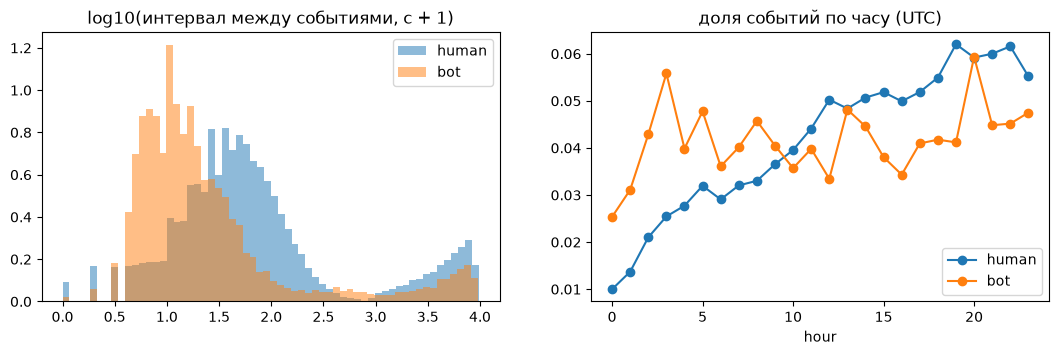

In [7]:
evw['t'] = evw.event_ts.astype('int64') / 1e6
evw['dt'] = evw.groupby('cookie_id').t.diff()
evw['hour'] = evw.event_ts.dt.hour
tm = evw[evw.target.notna()]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for k, lab in [(0, 'human'), (1, 'bot')]:
    x = tm.loc[tm.target == k, 'dt'].dropna()
    ax[0].hist(np.log10(x + 1), bins=60, density=True, alpha=.5, label=lab)
    tm.loc[tm.target == k, 'hour'].value_counts(normalize=True).sort_index().plot(ax=ax[1], marker='o', label=lab)
ax[0].set_title('log10(интервал между событиями, с + 1)'); ax[1].set_title('доля событий по часу (UTC)'); ax[0].legend(); ax[1].legend()
print(tm.groupby('target').dt.quantile([.1, .25, .5, .75, .9]).unstack().round(1))

In [8]:
g = evw.groupby('cookie_id')
sr = evw[evw.event_name == 'search_results_view'].groupby('cookie_id')
f = pd.DataFrame({
    'n_events': g.size(), 'dur_h': (g.t.max() - g.t.min()) / 3600,
    'dt_median': g.dt.median(), 'dt_cv': g.dt.std() / g.dt.mean(),
    'night_share': g.hour.apply(lambda s: (s < 6).mean()),
    'n_items': g.item_id.nunique(), 'n_locations': g.item_location.nunique(), 'n_categories': g.item_category.nunique(),
    'page_mean': sr.search_page.mean(), 'page_max': sr.search_page.max(),
    'queries_per_search': sr.search_query.nunique() / sr.size(),
    'ptr_share': g.pointer_x.apply(lambda s: s.notna().mean()),
    'ptr_x_std': g.pointer_x.std(), 'ptr_x_mean': g.pointer_x.mean(),
})
for e in ['item_view', 'photo_swipe', 'favorite_add', 'seller_page_view', 'login']:
    f['share_' + e] = g.event_name.apply(lambda s, e=e: (s == e).mean())
f = f.join(meta.set_index('cookie_id')[['target', 'cookie_created_at', 'window_start_ts', 'split']])
f['cookie_age_d'] = (f.window_start_ts - f.cookie_created_at).dt.total_seconds() / 86400
f = f.drop(columns=['cookie_created_at', 'window_start_ts'])
feats = f.columns.drop(['target', 'split'])
ft = f[f.target.notna()]
rows = []
for c in feats:
    ok = ft[c].notna()
    rows.append((c, roc_auc_score(ft.target[ok], ft[c][ok]), ft.loc[ft.target == 0, c].median(), ft.loc[ft.target == 1, c].median(), 1 - ok.mean()))
auc = pd.DataFrame(rows, columns=['feature', 'AUC', 'median_human', 'median_bot', 'nan_share'])
auc['|AUC-0.5|'] = (auc.AUC - .5).abs()
auc.sort_values('|AUC-0.5|', ascending=False).round(3)

,feature,AUC,median_human,median_bot,nan_share,|AUC-0.5|
12,ptr_x_std,0.064,552.898,202.539,0.646,0.436
13,ptr_x_mean,0.234,963.647,665.938,0.635,0.266
2,dt_median,0.273,60.500,25.000,0.023,0.227
8,page_mean,0.714,2.000,3.191,0.083,0.214
6,n_locations,0.711,5.000,8.000,0.000,0.211
9,page_max,0.708,4.000,7.000,0.083,0.208
10,queries_per_search,0.294,1.000,0.667,0.083,0.206
0,n_events,0.665,12.000,20.000,0.000,0.165
5,n_items,0.665,6.000,10.000,0.000,0.165
19,cookie_age_d,0.364,61.782,18.968,0.000,0.136


## 7. Сдвиг train/test и adversarial validation

In [9]:
X, y = f[feats].astype(float), (f.split == 'test').astype(int)
ks = sorted(((c, ks_2samp(X.loc[y == 0, c].dropna(), X.loc[y == 1, c].dropna()).statistic) for c in feats), key=lambda r: -r[1])
print('max KS train vs test:', [(c, round(v, 3)) for c, v in ks[:5]])
clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=config.SEED, verbose=-1)
cv = StratifiedKFold(5, shuffle=True, random_state=config.SEED)
p = cross_val_predict(clf, X, y, cv=cv, method='predict_proba')[:, 1]
print('adversarial ROC-AUC train vs test:', round(roc_auc_score(y, p), 4))
# контроль: то же самое внутри train, ранние дни против последних трёх (тест тоже лежит позже трейна)
mt = f.split == 'train'
late = (meta.set_index('cookie_id').loc[f.index[mt], 'window_start_ts'] >= '2026-04-17').astype(int).values
p2 = cross_val_predict(clf, X[mt], late, cv=cv, method='predict_proba')[:, 1]
print('adversarial ROC-AUC внутри train (до/после 04-17):', round(roc_auc_score(late, p2), 4))
print('adversarial AUC по признаку «есть события вне окна» (если бы не фильтровали): test=0 у всех, train:',
      m[m.split == 'train'].groupby('cookie_id').inw.apply(lambda s: (~s).any()).mean().round(3))

max KS train vs test: [('ptr_x_std', np.float64(0.046)), ('page_mean', np.float64(0.032)), ('ptr_x_mean', np.float64(0.029)), ('page_max', np.float64(0.026)), ('dt_median', np.float64(0.021))]


adversarial ROC-AUC train vs test: 0.4951


adversarial ROC-AUC внутри train (до/после 04-17): 0.4881


adversarial AUC по признаку «есть события вне окна» (если бы не фильтровали): test=0 у всех, train: 0.476


## Выводы
1. **Баланс.** 899 ботов из 11 091 (8.1%), доля стабильна по дням (6-9%). Константа даёт P@R >= 0.7 около 0.08.
2. **Время.** Окна длятся ровно сутки. Train покрывает 6-19 апреля, test 20-26 апреля, то есть тест строго позже. Всё в UTC с точностью до секунды, парсинг одинаковый.
3. **Окно `[start, end)`.** После окна 40 711 событий, ровно на `end` 68, до начала ни одного. Кук без событий после фильтра нет.
4. **Утечка.** События вне окна есть только у train (у 77% ботов и 45% людей), и там же все 7 928 показов капчи, 88% из них у ботов. Это реакция системы уже после детекции, поэтому фильтр по окну обязателен. Внутри окна капчи не бывает вообще.
5. **Дубли.** В окне 4 293, доля около 1.5% и одинаковая у классов, значит технический артефакт. Удаляю, а число дублей оставляю слабым признаком (AUC 0.56, и то в основном через число событий).
6. **Пропуски структурные.** Зависят от типа события (у логина и выдачи нет полей объявления, поиск только в выдаче) и платформы (курсор только на web, там 41% пустых). Импутацию не делаю, сами пропуски тоже информативны.
7. **platform.** 11 написаний случайно чередуются внутри куки и от таргета не зависят, свожу их к web, android, ios. Ботов больше на web (9.9%), меньше на ios (4.5%).
8. **user_agent.** 148 значений, все есть и в train, и в test. Среди автоматических UA (curl, Scrapy, Headless, python) ботов только 20-27%, стопроцентных ярлыков нет. Сигнал средний, риск шортката небольшой, но модель без UA всё равно проверю.
9. **Курсор (web).** Самый сильный сигнал: у ботов узкий разброс и смещение по X (std 203 против 553, AUC 0.94 в инверсии). У многих web-ботов курсора нет совсем.
10. **Темп.** Боты кликают чаще и ровнее: медиана интервала 14 с против 47 с, пик в районе 2-20 с. При этом совсем быстрых интервалов (меньше секунды) у ботов не больше, чем у людей.
11. **Поиск.** Боты глубже листают выдачу (средняя страница 3.2 против 2.0), задают меньше разных запросов на просмотр выдачи и смотрят больше городов.
12. **Типы событий.** У ботов больше item_view и seller_page_view, меньше photo_swipe и favorite_add. Контакты и логин почти не отличаются.
13. **Возраст куки.** У ботов куки моложе (медиана 19 дней против 62).
14. **Сдвиг.** Adversarial ROC-AUC train против test 0.50, внутри train между ранними и поздними днями 0.49, KS не больше 0.05. Сдвига нет.
15. **Валидация.** Основная схема StratifiedKFold(5), плюс контрольный time-holdout на окнах с 17 апреля, потому что тест лежит позже по времени.